# Tree growth figures


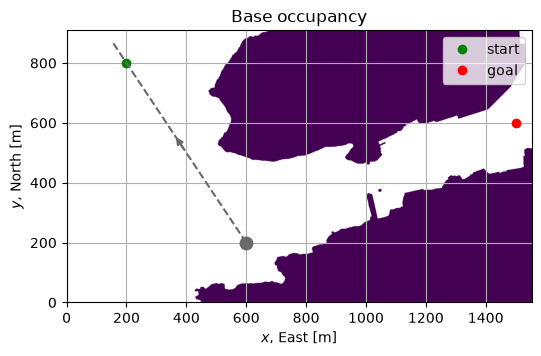

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from cartoblobpy.graph import Graph

from risk_informed_planner.obstacles import *
from risk_informed_planner.visualization import *

g = Graph()
g.load_from_yaml("../maps/kristiansund_bridge/map.yaml")
# g.goal = (1850.0, 1800.0)
g.start = (200.0, 800.0)
g.goal = (1500, 600.0)
obstacles = [
    # LinearDynamicObstacle.create(start_pose=(1450.0, 600.0), end_pose=(500.0, 250.0), velocity=3.0),
    LinearDynamicObstacle.create(start_pose=(600.0, 200.0), end_pose=(200.0, 800.0), velocity=2.0),
    # LinearDynamicObstacle.create(start_pose=(500.0, 700.0), end_pose=(100.0, 100.0), velocity=1.0),
    # LinearDynamicObstacle.create(start_pose=(1500.0, 1100.0), end_pose=(250.0, 1100.0), velocity=3.0),
    # LinearDynamicObstacle.create(start_pose=(2300.0, 1800.0), end_pose=(5400.0, 4000.0), velocity=5.0),
]

fig, ax = plt.subplots(figsize=(6, 6))


g.plot(ax=ax)
plot_obstacles(obstacles, ax=ax, max_time=400.0)
plt.grid(True)

In [2]:
from risk_informed_planner.config import Config
from risk_informed_planner.risk import cost_model
from risk_informed_planner.risk.dynamic_risk import DynamicRisk
from risk_informed_planner.planner import (
    RiskAwareAngleCostRRTStarSearch,
)
from risk_informed_planner.utils import Node

start = Node(g.start[0], g.start[1], 0)
goal = Node(g.goal[0], g.goal[1], -1)


/opt/homebrew/Caskroom/miniconda/base/envs/sandbox3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import time
import copy

from risk_informed_planner.planner import progress_bar

# Largest tree size we want a heatmap for -- also cfg.MAX_NODES, since the
# run needs to grow at least this far.
node_count_targets = [750, 1000, 1250, 1500, 1750, 2000, 2250, 2500]
max_nodes = max(node_count_targets)

cfg = Config(
    X_LIMITS=(0, g.width),
    Y_LIMITS=(0, g.height),
    STEP_SIZE=50,
    GOAL_RADIUS=75,
    NEIGHBOR_RADIUS=150,
    MAX_NODES=max_nodes,
    # MAX_NEIGHBORS_RISK_RENEWAL=None,
    ALPHA=0.1,
    BETA=100.0,
    GAMMA=0.6,
    MAX_TURN_ANGLE=np.pi / 4.0,
    # RISK_CUTOFF=0.20,
    RISK_SAMPLE_SPACING=30.0,
    RISK_AGGREGATION="max"
)

min_depth=6.0
risk_model = DynamicRisk(
    max_distance_from_shore=150.0,
    lookahead_distance=150.0,
    graph=g,
    obstacles=obstacles,
    max_dcpa_for_collision_risk=50.0,
    max_tcpa_for_collision_risk=120.0,
    max_relative_velocity_for_collision_risk=6.0,
    grounding_depth_hard_limit=min_depth,
    desired_speed=3.0,
    cost_model=cost_model.NormalizedExpectedLoss(),
)

# --- snapshot machinery ---------------------------------------------------
# We want the heatmaps at 750/1000/.../2500 nodes to come from the *same*
# random tree, not from 8 separately-seeded runs (which would each explore
# differently). So we grow a single run to max_nodes and, every time the
# tree first reaches one of `node_count_targets`, deep-copy the current
# nodes/path into `snapshots`.
#
# A deep copy is required (not just `list(nodes)`) because RRT* rewires
# earlier nodes in place as the tree grows -- a shallow copy of the node
# list would keep the right *set* of nodes but their .cost/.risk/.parent
# would silently drift to their final-run values by the time we plot them.
# `bbn_snapshot` is a plain dict of floats/strings (see
# BBN.snapshot()), so deep-copying it is cheap and safe.
snapshots: dict[int, dict] = {}
_run_start_time = None  # set right before calling path_planner()

def snapshot_callback(nodes, path, planner_obj):
    elapsed = time.perf_counter() - _run_start_time
    current_count = len(nodes)
    for target in node_count_targets:
        if target not in snapshots and current_count >= target:
            snapshots[target] = dict(
                nodes=copy.deepcopy(nodes),
                path=copy.deepcopy(path),
                elapsed=elapsed,
                count=current_count,
            )

path_planner = RiskAwareAngleCostRRTStarSearch(
    start=start,
    goal=goal,
    graph=g,
    cfg=cfg,
    risk_model=risk_model,
    callback_functions=[progress_bar, snapshot_callback],
    record_bbn_snapshots=True,
    min_depth=min_depth,
    free_check_method=RiskAwareAngleCostRRTStarSearch.FreeCheckMethod.DEPTH_SAMPLING_OCCUPANCY_CHECKS
)


In [4]:
_run_start_time = time.perf_counter()
nodes, path = path_planner()
total_computation_time = time.perf_counter() - _run_start_time
print(f"Planning completed in {total_computation_time:.2f} seconds ({len(nodes)} nodes total).")

missing = [t for t in node_count_targets if t not in snapshots]
if missing:
    print(f"Warning: tree only reached {len(nodes)} nodes, never hit {missing}.")

print("\nComputation time to reach each tree size:")
for target in node_count_targets:
    if target in snapshots:
        snap = snapshots[target]
        print(f"  {target:>4} nodes: t={snap['elapsed']:6.2f}s (tree had {snap['count']} nodes)")


Progress: 100%|██████████| 2500/2500 [01:03<00:00, 39.10node/s, Path=21]


Planning completed in 64.39 seconds (2500 nodes total).

Computation time to reach each tree size:
   750 nodes: t=  6.87s (tree had 750 nodes)
  1000 nodes: t= 11.41s (tree had 1000 nodes)
  1250 nodes: t= 17.18s (tree had 1250 nodes)
  1500 nodes: t= 24.12s (tree had 1500 nodes)
  1750 nodes: t= 32.49s (tree had 1750 nodes)
  2000 nodes: t= 41.94s (tree had 2000 nodes)
  2250 nodes: t= 52.76s (tree had 2250 nodes)
  2500 nodes: t= 64.03s (tree had 2500 nodes)


In [5]:
from risk_informed_planner.visualization import *

# Risk / collision / grounding heatmap for every snapshot, all drawn from
# the same run's tree at different stages of growth.
save_dir = "plots/node_count_sweep"
enable_latex(True)
for target in node_count_targets:
    if target not in snapshots:
        continue
    snap = snapshots[target]
    save_prefix = f"nodes_{target:04d}_"
    plot_paper_panels(
        nodes=snap["nodes"],
        path=snap["path"],
        cfg=cfg,
        graph=g,
        obstacles=obstacles,
        t_computation=snap["elapsed"],
        speed=risk_model.desired_speed,
        metrics=("risk",),
        modes=("heatmap",),
        vmin={"risk": 0.03},
        vmax={"risk": 0.10},
        latex=False,
        save_dir=save_dir,
        save_prefix=save_prefix,
    )
    plt.close('all')

print(f"Saved heatmaps for {len(snapshots)} node counts to '{save_dir}'.")


Saved heatmaps for 8 node counts to 'plots/node_count_sweep'.


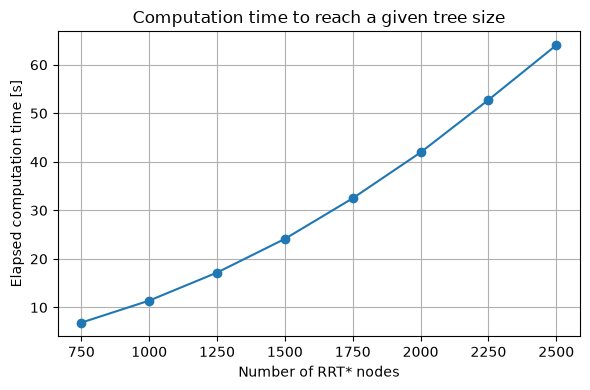

In [6]:
targets_reached = [t for t in node_count_targets if t in snapshots]
times_reached = [snapshots[t]["elapsed"] for t in targets_reached]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(targets_reached, times_reached, marker='o', color='tab:blue')
ax.set_xlabel("Number of RRT* nodes")
ax.set_ylabel("Elapsed computation time [s]")
ax.set_title("Computation time to reach a given tree size")
ax.grid(True)
fig.tight_layout()
fig.savefig(f"{save_dir}/computation_time_vs_node_count.pdf")
